# Example: cord blood LARRY data from CLADES

Human cord blood LARRY lineage tracing (days 3, 10, 17) published with CLADES (Gao, Barile et al., Nat Commun 2025;
data on figshare, CC BY 4.0). Input: `inputs/cord_blood_clades/`, 606 clones x 31 timepoint_celltype columns (cells
per clone) and the 12 CLADES meta-clones.

1. **Test.** clomet (Leiden at 30 resolutions, consensus matrix, tree) on the same input as CLADES (raw counts,
   Euclidean distance, 15 neighbours), compared with the CLADES meta-clones.
2. **New meta-clones.** clomet with its default input (log1p, cosine distance, 25 neighbours): choosing k, the
   meta-clones, a clone UMAP, the clone heatmap and the comparison with the CLADES meta-clones.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns
import scanpy as sc
import plotly.io as pio
from scipy.cluster.hierarchy import linkage, fcluster, leaves_list
from scipy.spatial.distance import pdist
from sklearn.metrics import adjusted_rand_score

import clomet

warnings.filterwarnings('ignore')
sc.set_figure_params(scanpy=False, dpi=100)
pio.renderers['png'].scale = 1.5

inputs = Path('../inputs/cord_blood_clades')
counts = pd.read_csv(inputs / 'clone_counts.csv', index_col='clone')
clades = pd.read_csv(inputs / 'clades_metaclones.csv', index_col='clone', dtype=str).clades_meta_clone
clades_order = sorted(clades.unique(), key=int)
print(f'{counts.shape[0]} clones x {counts.shape[1]} columns, {counts.values.sum():,} cells, '
      f'{clades.nunique()} CLADES meta-clones')
counts.iloc[:5, :6]

606 clones x 31 columns, 11,064 cells, 12 CLADES meta-clones


,Day10_DC,Day10_DC precursor,Day10_Early Erythroid,Day10_HSC/MPP 1,Day10_HSC/MPP 2,Day10_Late Erythroid
clone,,,,,,
Clone_1,0,0,1,0,0,0
Clone_3,0,0,1,0,0,0
Clone_6,0,0,2,0,0,1
Clone_12,0,0,2,0,0,0
Clone_13,0,0,1,0,0,0


## 1. Test: clomet against the CLADES meta-clones

### Check of the input

CLADES made its meta-clones with one Leiden run (PCA, 15 neighbours, resolution 1) on the raw counts. Running that
same step on the clone table here should give back the CLADES meta-clones; if it does, the table matches the one
CLADES used. This step is only a check and is not part of clomet.

In [2]:
m = sc.AnnData(counts.values.astype(np.float32))
sc.tl.pca(m, n_comps=30, random_state=0)
sc.pp.neighbors(m, n_neighbors=15)
sc.tl.leiden(m, resolution=1, random_state=0, flavor='leidenalg')
print(f'CLADES clustering re-run: {m.obs.leiden.nunique()} clusters, adjusted Rand index to the CLADES meta-clones '
      f'{adjusted_rand_score(clades, m.obs.leiden):.3f}')

CLADES clustering re-run: 12 clusters, adjusted Rand index to the CLADES meta-clones 0.865


### clomet on the CLADES input

clomet on the same input as CLADES (`log1p=False`, Euclidean distance, 15 neighbours, 30 principal components): Leiden
at 30 resolutions (0.2-3.1), the consensus matrix of the partitions, the average-linkage tree, cut at k = 12 (the
number of CLADES meta-clones).

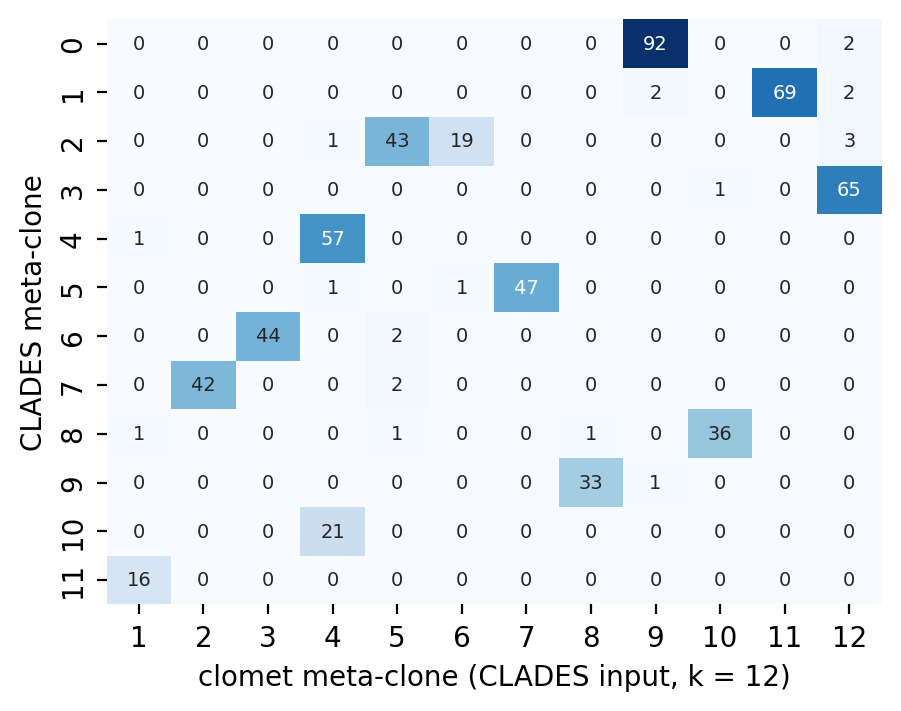

clomet vs CLADES meta-clones: adjusted Rand index 0.860; 11 of 12 CLADES meta-clones have >= 90 % of their clones in one clomet meta-clone


In [3]:
test = clomet.assign(counts, k=12, k_range=[12], log1p=False, metric='euclidean', n_neighbors=15, n_pcs=30)
tab = pd.crosstab(clades, test.clusters).loc[clades_order]
fig, ax = plt.subplots(figsize=(5, 3.8))
sns.heatmap(tab, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax, annot_kws=dict(fontsize=7))
ax.set_xlabel('clomet meta-clone (CLADES input, k = 12)'); ax.set_ylabel('CLADES meta-clone')
plt.show()
share = tab.div(tab.sum(axis=1), axis=0).max(axis=1)
print(f'clomet vs CLADES meta-clones: adjusted Rand index {adjusted_rand_score(clades, test.clusters):.3f}; '
      f'{(share >= 0.9).sum()} of {len(share)} CLADES meta-clones have >= 90 % of their clones in one clomet meta-clone')

## 2. New meta-clones with clomet's default input

log1p, PCA (30 components, as the matrix has 31 columns), 25 neighbours with cosine distance, Leiden at resolutions
0.2-3.1, consensus, average-linkage tree.

### Choosing k

Tree cuts k = 4, 6, …, 20: cluster sizes and how uneven they are, agreement between cuts (adjusted Rand index), how
clones move between clusters from one cut to the next, and the consensus matrix for some cuts.

30 resolutions, 13 partitions used (k = [6, 7, 9, 13, 14, 15, 16, 17, 19, 20, 21, 22, 24])


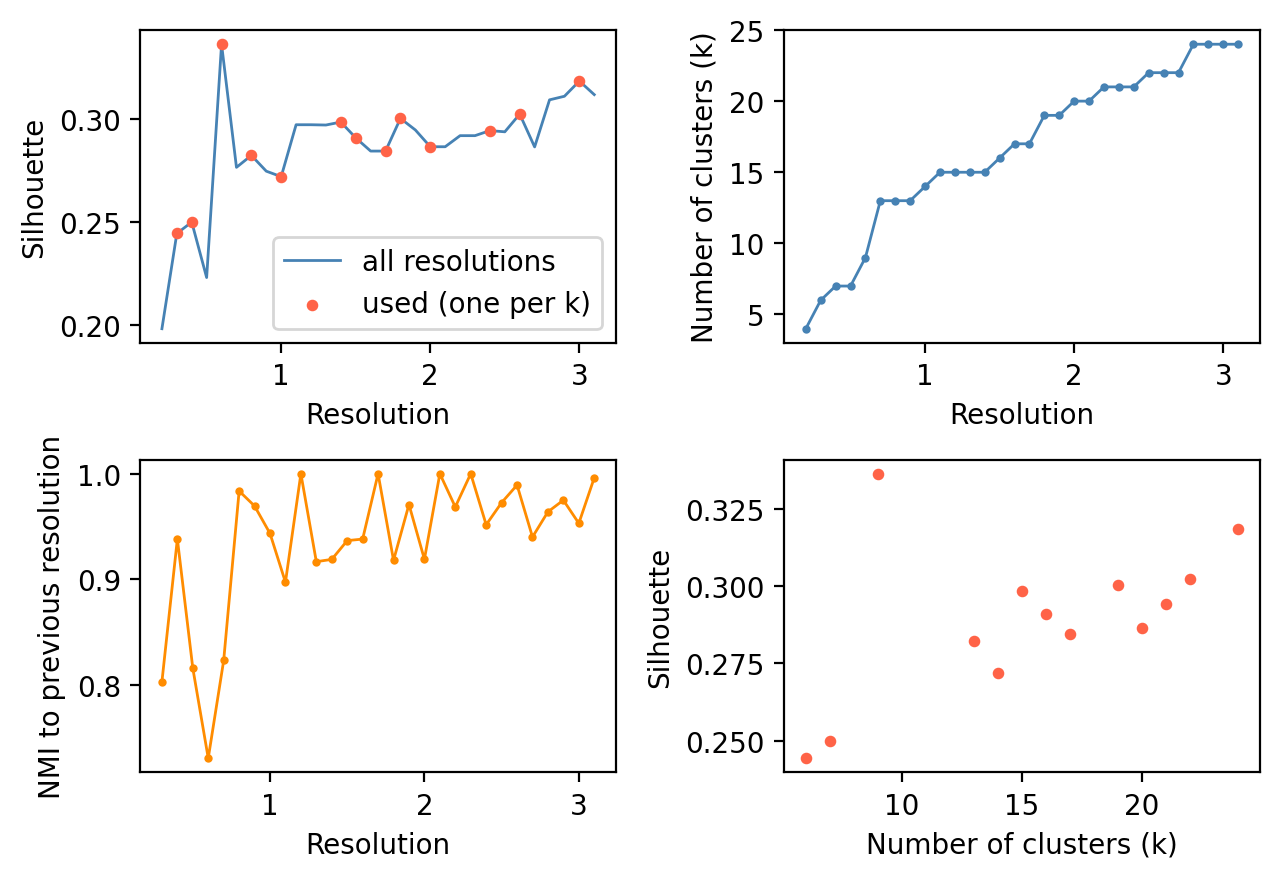

In [4]:
k_range = list(range(4, 21, 2))
res = clomet.assign(counts, k=14, k_range=k_range, n_pcs=30)
print(f'{len(res.scan)} resolutions, {len(res.used)} partitions used (k = {res.used.k.tolist()})')
clomet.pl.resolution_scan(res.scan, res.used)
plt.show()

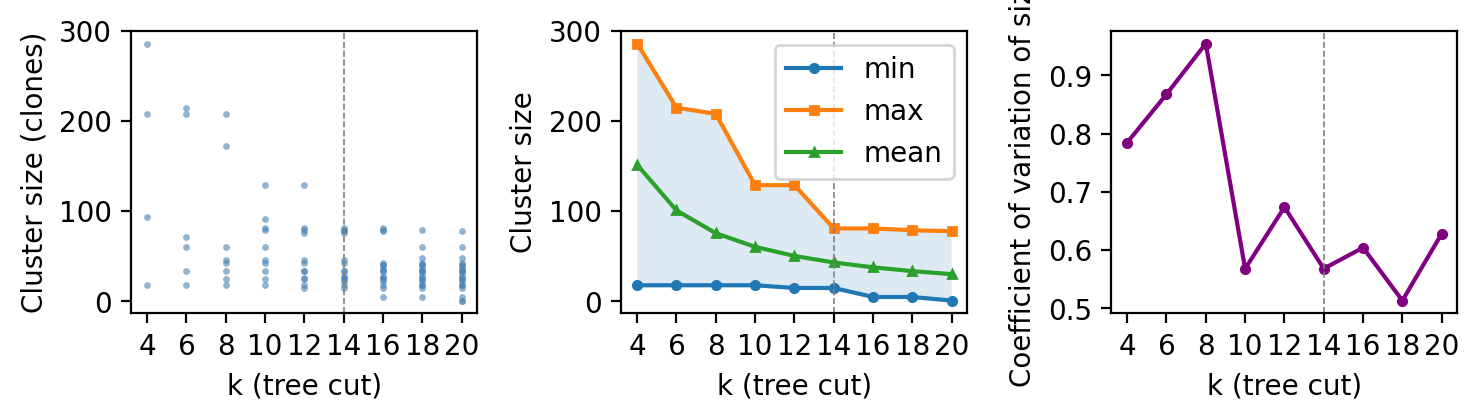

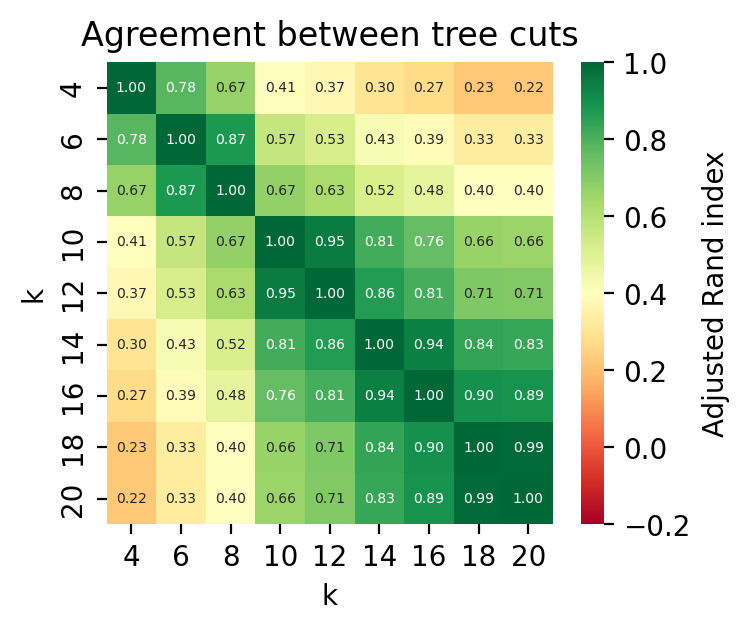

,k,n_clusters,min_size,max_size,mean_size,cv_size
0,4,4,18,286,151.500000,0.784813
1,6,6,18,215,101.000000,0.867724
2,8,8,18,208,75.750000,0.954748
3,10,10,18,129,60.600000,0.568194
4,12,12,15,129,50.500000,0.673982
5,14,14,15,81,43.285714,0.568453
6,16,16,5,81,37.875000,0.604374
7,18,18,5,79,33.666667,0.513562
8,20,20,1,78,30.300000,0.628396


In [5]:
clomet.pl.choose_k(res.cuts, res.k_summary, k_range, chosen=14)
plt.show()
clomet.pl.cut_ari(res.ari)
plt.show()
res.k_summary

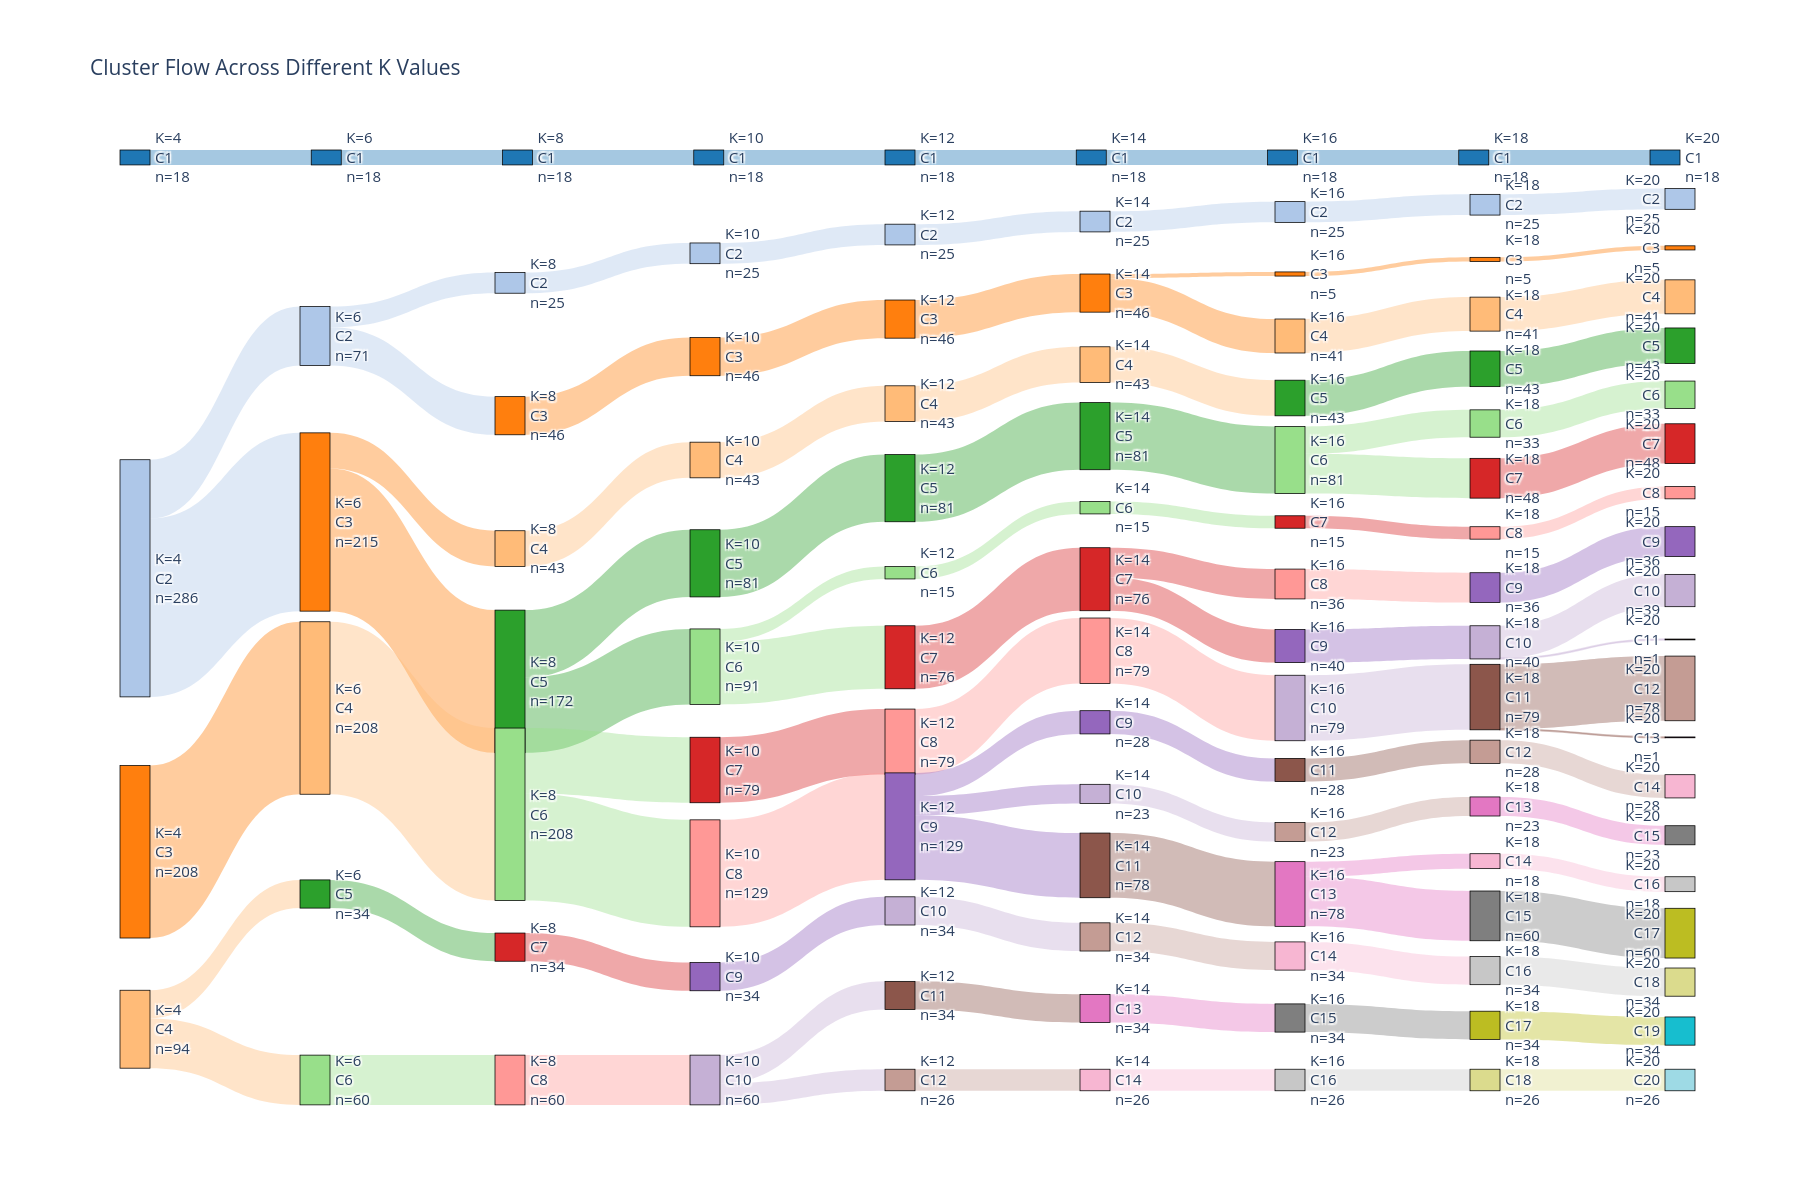

In [6]:
clomet.pl.sankey(res.cuts, k_range).show(renderer='png')

The smallest cluster has 15-18 clones up to k = 14 and 5 clones from k = 16, and the cluster sizes are least
uneven at k = 14 (with k = 10). The tree is cut at k = 14, without splits.

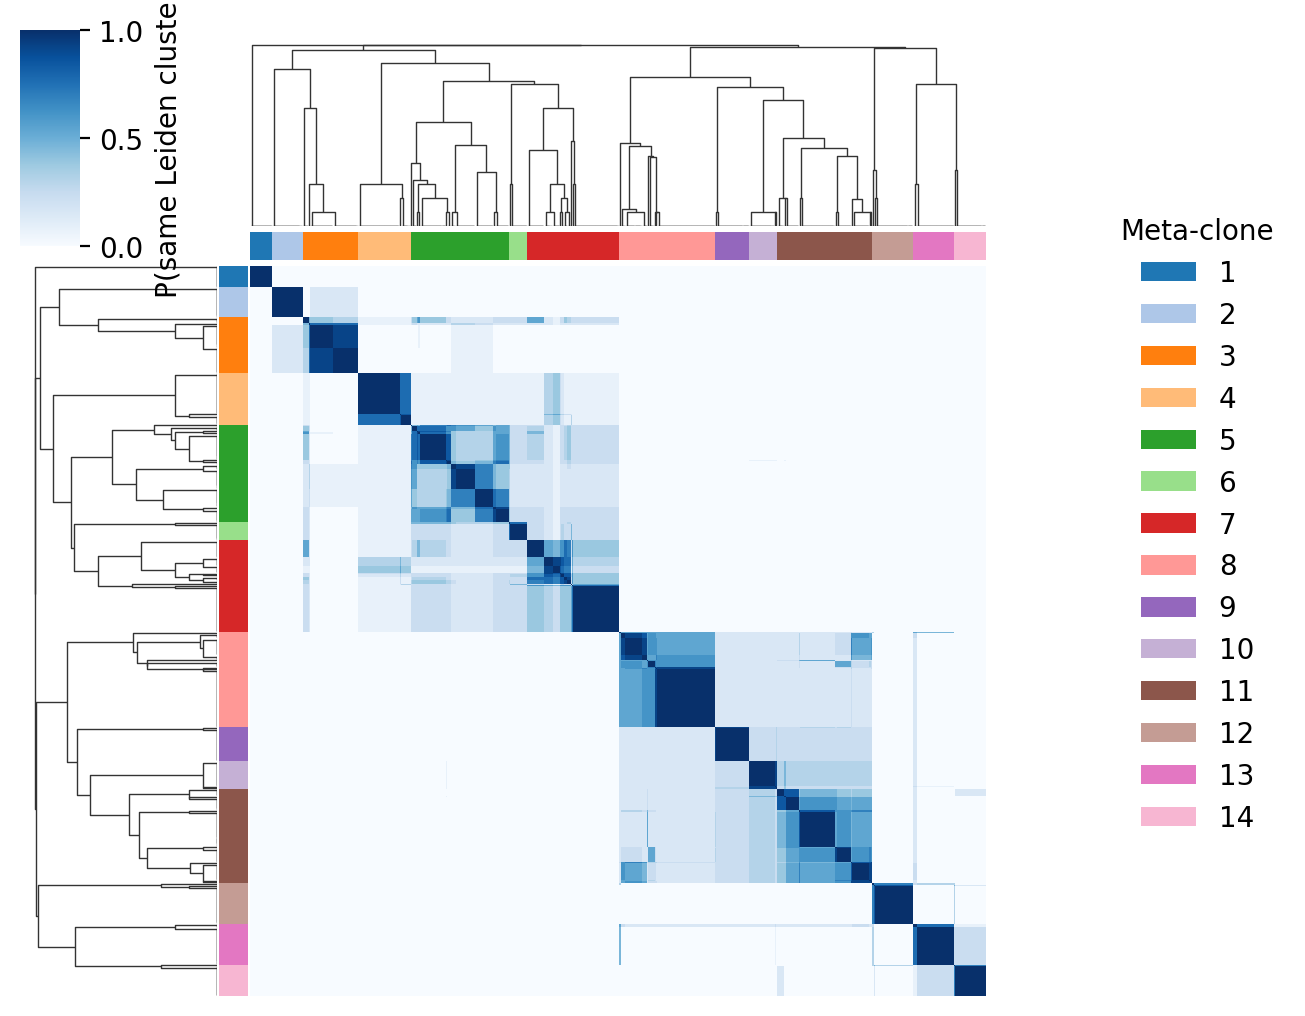

meta_clone,1,2,3,4,5,6,7,8,9,10,11,12,13,14
clones,18,25,46,43,81,15,76,79,28,23,78,34,34,26


In [7]:
k = 14
labels = res.cuts[f'k_{k}'].astype(str).rename('meta_clone')
mtc_order = sorted(labels.unique(), key=int)
mtc_colors = dict(zip(mtc_order, sns.color_palette('tab20', len(mtc_order)).as_hex()))
clomet.pl.coassociation(res.coassoc, res.tree, labels, mtc_colors)
plt.show()
labels.value_counts().reindex(mtc_order).rename('clones').to_frame().T

### Clone UMAP

From the same neighbour graph, coloured by the new and by the CLADES meta-clones.

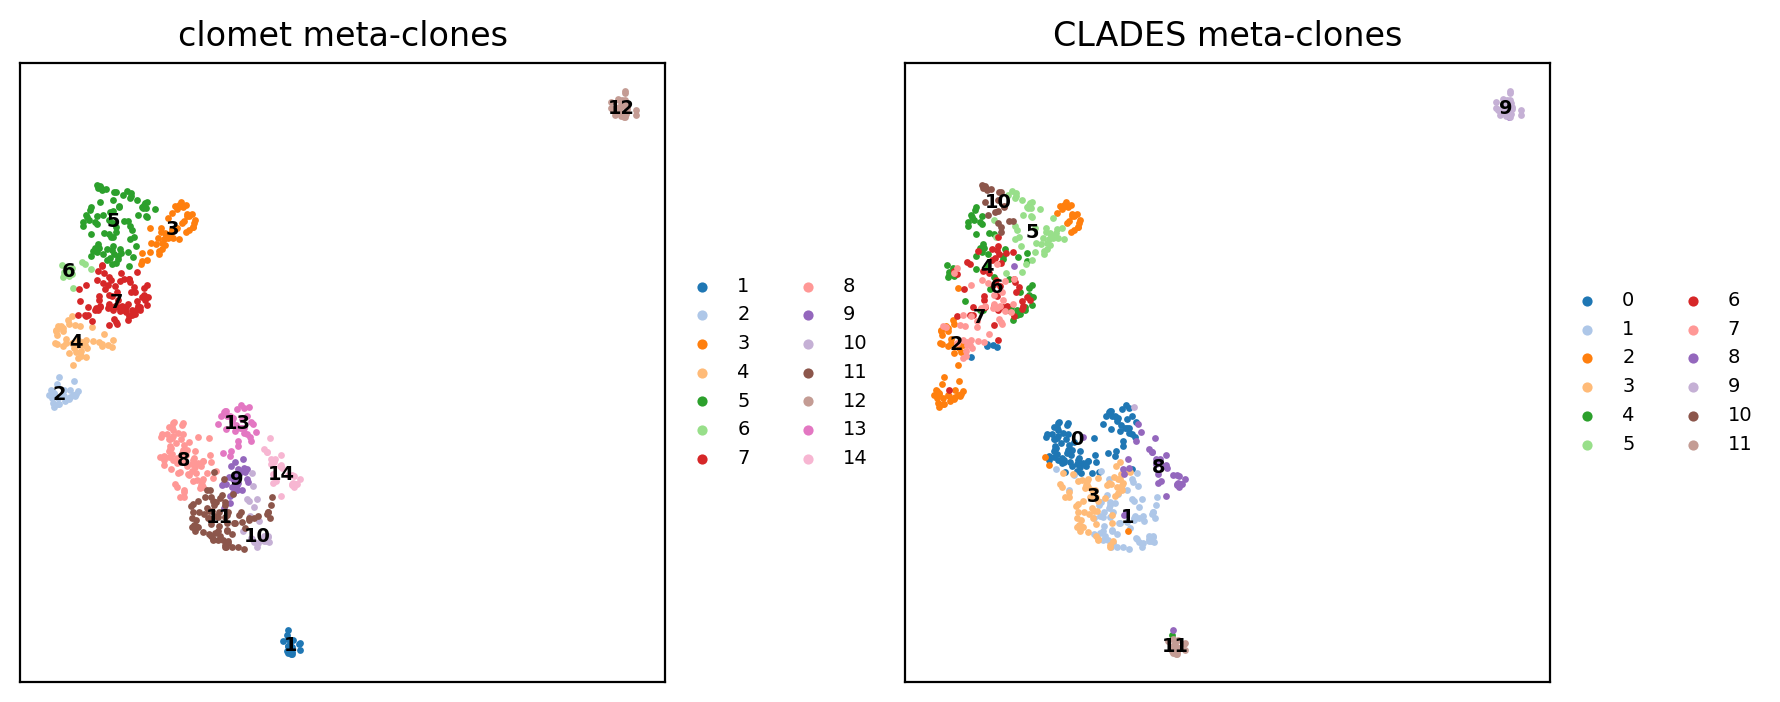

In [8]:
sc.tl.umap(res.adata, random_state=0)
xy = pd.DataFrame(res.adata.obsm['X_umap'], index=counts.index, columns=['umap1', 'umap2'])
clades_colors = dict(zip(clades_order, sns.color_palette('tab20', len(clades_order)).as_hex()))
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, lab, order, colors, title in [(axes[0], labels, mtc_order, mtc_colors, 'clomet meta-clones'),
                                      (axes[1], clades, clades_order, clades_colors, 'CLADES meta-clones')]:
    for g in order:
        d = xy[lab == g]
        ax.scatter(d.umap1, d.umap2, s=6, c=colors[g], lw=0, label=g)
        ax.text(d.umap1.median(), d.umap2.median(), g, fontsize=7, weight='bold', ha='center', va='center')
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title)
    ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), ncol=2, markerscale=1.5, fontsize=7, frameon=False)
fig.tight_layout()
plt.show()

### Clone heatmap

Clones grouped by meta-clone, the 31 timepoint_celltype columns as rows, log1p(cells). Within a meta-clone, clones are
ordered by their day 3 profile, then by days 10 + 17 (correlation distance; a clone with no cells on those days counts
as unrelated to the others).

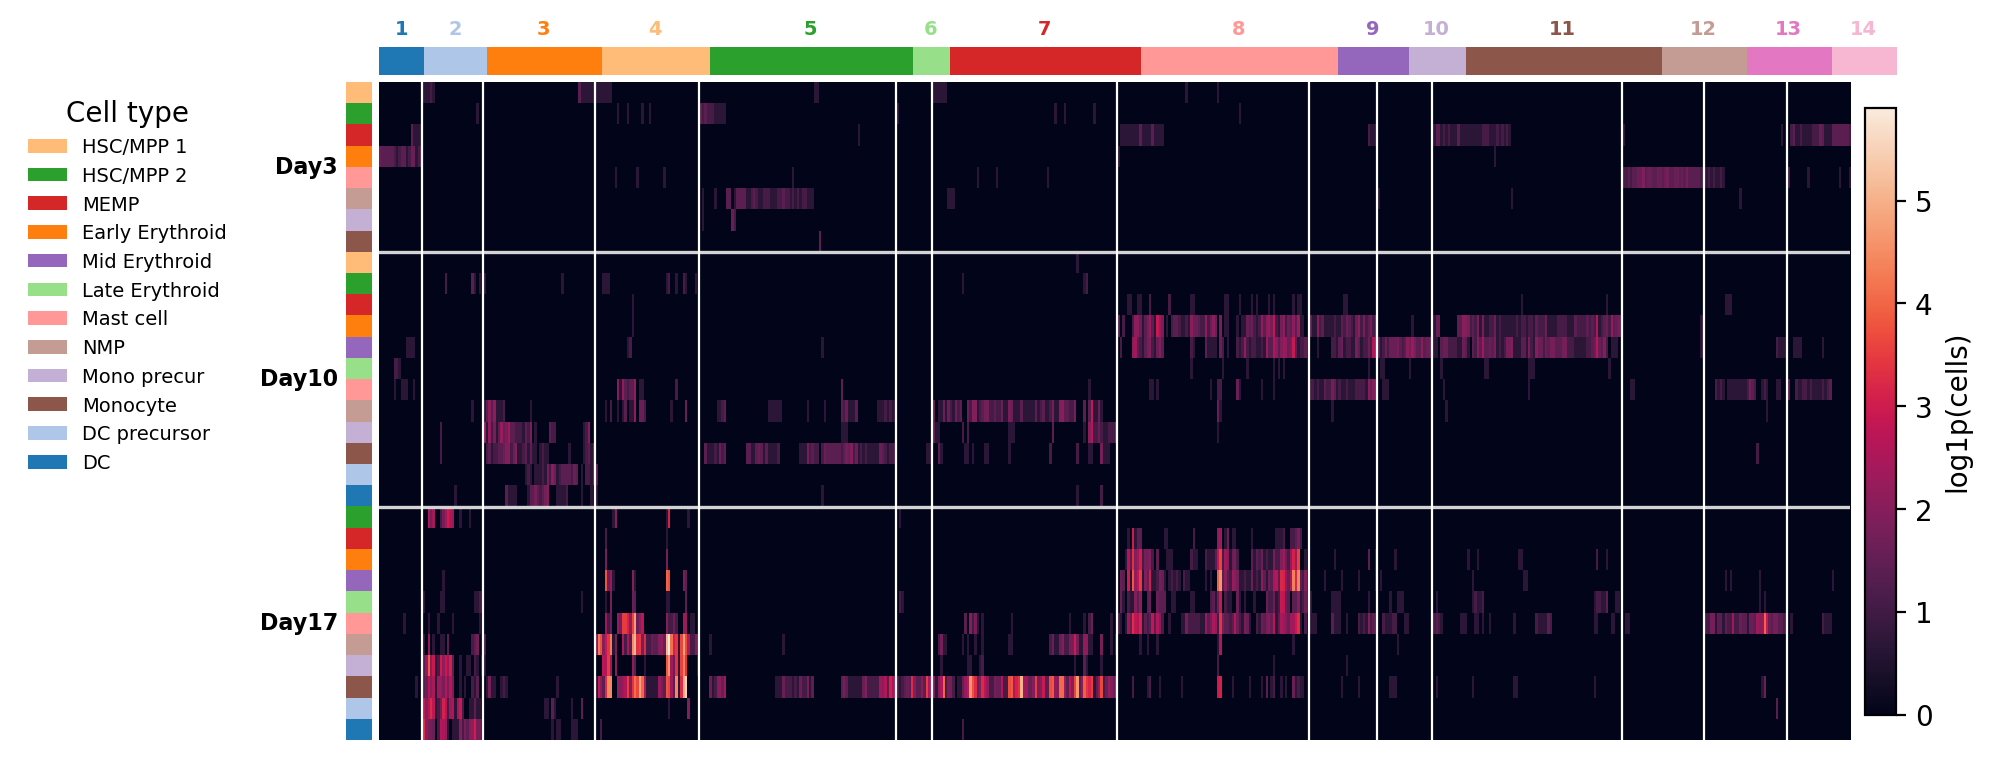

In [9]:
def corr_linkage(x):
    x = np.asarray(x, dtype=float)
    flat = x.std(axis=1) == 0
    d = pdist(x, metric='correlation')
    i, j = np.triu_indices(len(x), k=1)
    d[flat[i] & flat[j]] = 0.0
    d[flat[i] ^ flat[j]] = 1.0
    return linkage(np.nan_to_num(d, nan=1.0), method='average')


def order_d3_then_later(sub, d3, later, per_group=20, k_min=2, k_max=10):
    if len(sub) == 1:
        return [0]
    z3 = corr_linkage(sub[d3].values)
    k = max(k_min, min(k_max, len(sub) // per_group))
    groups = fcluster(z3, t=k, criterion='maxclust') if len(sub) >= 2 * k else np.ones(len(sub), int)
    order = []
    for grp in dict.fromkeys(groups[i] for i in leaves_list(z3)):
        idx = np.where(groups == grp)[0]
        if len(idx) > 1:
            idx = idx[leaves_list(corr_linkage(sub.iloc[idx][later].values))]
        order.extend(idx.tolist())
    return order


ct_colors = {'HSC/MPP 1': '#ffbb78', 'HSC/MPP 2': '#2ca02c', 'MEMP': '#d62728', 'Early Erythroid': '#ff7f0e',
             'Mid Erythroid': '#9467bd', 'Late Erythroid': '#98df8a', 'Mast cell': '#ff9896', 'NMP': '#c49c94',
             'Mono precur': '#c5b0d5', 'Monocyte': '#8c564b', 'DC precursor': '#aec7e8', 'DC': '#1f77b4'}
days = ['Day3', 'Day10', 'Day17']
feat = [f'{d}_{c}' for d in days for c in ct_colors if f'{d}_{c}' in counts.columns]
d3 = [f for f in feat if f.startswith('Day3_')]
later = [f for f in feat if not f.startswith('Day3_')]
logc = np.log1p(counts[feat])
col_order, bounds = [], [0]
for g in mtc_order:
    sub = logc[labels == g]
    col_order += list(sub.index[order_d3_then_later(sub, d3, later)])
    bounds.append(len(col_order))
n_day = [sum(f.startswith(f'{d}_') for f in feat) for d in days]

fig = plt.figure(figsize=(10, 4.5))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 60], height_ratios=[1.3, 30], wspace=0.01, hspace=0.02)
ax_top, ax_strip, ax = fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1])
im = ax.imshow(logc.loc[col_order, feat].T.values, aspect='auto', cmap='rocket', interpolation='nearest')
for y in np.cumsum(n_day)[:-1]:
    ax.axhline(y - 0.5, c='lightgrey', lw=1.2)
for b in bounds[1:-1]:
    ax.axvline(b - 0.5, c='white', lw=0.8)
ax.set_xticks([]); ax.set_yticks([])
ax_strip.imshow(np.array([matplotlib.colors.to_rgb(ct_colors[f.split('_', 1)[1]]) for f in feat])[:, None, :],
                aspect='auto', interpolation='nearest')
ax_strip.set_xticks([]); ax_strip.set_yticks([])
for d, start, n in zip(days, np.r_[0, np.cumsum(n_day)[:-1]], n_day):
    ax_strip.text(-0.8, start + n / 2 - 0.5, d, ha='right', va='center', fontsize=8, fontweight='bold')
ax_top.imshow(np.array([matplotlib.colors.to_rgb(mtc_colors[labels[c]]) for c in col_order])[None, :, :],
              aspect='auto', interpolation='nearest')
ax_top.set_xticks([]); ax_top.set_yticks([])
for i, g in enumerate(mtc_order):
    ax_top.text((bounds[i] + bounds[i + 1]) / 2 - 0.5, -0.8, g, ha='center', va='bottom', fontsize=7,
                fontweight='bold', color=mtc_colors[g])
for a in [ax, ax_strip, ax_top]:
    for s in a.spines.values():
        s.set_visible(False)
ax_strip.legend(handles=[Patch(fc=c, label=t) for t, c in ct_colors.items()], title='Cell type', loc='upper right',
                bbox_to_anchor=(-4, 1.0), fontsize=7, frameon=False)
fig.colorbar(im, ax=ax, fraction=0.02, pad=0.01).set_label('log1p(cells)')
plt.show()

### New meta-clones against the CLADES meta-clones

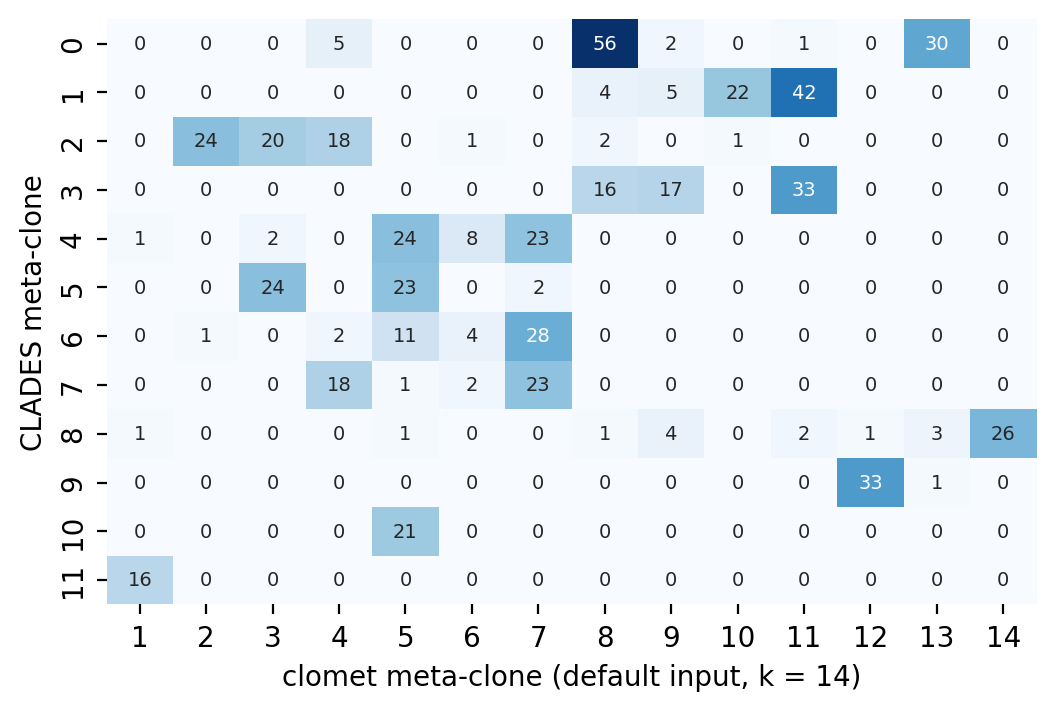

adjusted Rand index to the CLADES meta-clones: 0.385


,meta_clone,clades_meta_clone
clone,,
Clone_1,11,1
Clone_3,11,1
Clone_6,11,3
Clone_12,11,3
Clone_13,11,3


In [10]:
tab = pd.crosstab(clades, labels).loc[clades_order, mtc_order]
fig, ax = plt.subplots(figsize=(6, 3.8))
sns.heatmap(tab, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax, annot_kws=dict(fontsize=7))
ax.set_xlabel('clomet meta-clone (default input, k = 14)'); ax.set_ylabel('CLADES meta-clone')
plt.show()
print(f'adjusted Rand index to the CLADES meta-clones: {adjusted_rand_score(clades, labels):.3f}')
pd.DataFrame({'meta_clone': labels, 'clades_meta_clone': clades}).head()